In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
airfare = pd.read_csv('airq402.dat', sep='\s+', header=None)
airfare.head()

,0,1,2,3,4,5,6,7,8,9,10
0,CAK,ATL,114.47,528,424.56,FL,70.19,111.03,FL,70.19,111.03
1,CAK,MCO,122.47,860,276.84,FL,75.10,123.09,DL,17.23,118.94
2,ALB,ATL,214.42,852,215.76,DL,78.89,223.98,CO,2.77,167.12
3,ALB,BWI,69.40,288,606.84,WN,96.97,68.86,WN,96.97,68.86
4,ALB,ORD,158.13,723,313.04,UA,39.79,161.36,WN,15.34,145.42


In [3]:
airfare.columns = [
    'origin', 'dest', 'avg_fare', 'passengers', 'distance',
    'carrier1', 'carrier1_share', 'carrier1_fare',
    'carrier2', 'carrier2_share', 'carrier2_fare'
]
airfare.head()

,origin,dest,avg_fare,passengers,distance,carrier1,carrier1_share,carrier1_fare,carrier2,carrier2_share,carrier2_fare
0,CAK,ATL,114.47,528,424.56,FL,70.19,111.03,FL,70.19,111.03
1,CAK,MCO,122.47,860,276.84,FL,75.10,123.09,DL,17.23,118.94
2,ALB,ATL,214.42,852,215.76,DL,78.89,223.98,CO,2.77,167.12
3,ALB,BWI,69.40,288,606.84,WN,96.97,68.86,WN,96.97,68.86
4,ALB,ORD,158.13,723,313.04,UA,39.79,161.36,WN,15.34,145.42


In [4]:
airfare_encoded = pd.get_dummies(airfare, columns=['origin', 'dest', 'carrier1', 'carrier2'])
print(airfare_encoded.shape)
airfare_encoded.head()

(1000, 217)


,avg_fare,passengers,distance,carrier1_share,carrier1_fare,carrier2_share,carrier2_fare,origin_ABQ,origin_ACY,origin_ALB,...,carrier2_G4,carrier2_HP,carrier2_NK,carrier2_NW,carrier2_SY,carrier2_TZ,carrier2_UA,carrier2_US,carrier2_WN,carrier2_YX
0,114.47,528,424.56,70.19,111.03,70.19,111.03,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,122.47,860,276.84,75.10,123.09,17.23,118.94,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,214.42,852,215.76,78.89,223.98,2.77,167.12,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,69.40,288,606.84,96.97,68.86,96.97,68.86,0,0,1,...,0,0,0,0,0,0,0,0,1,0
4,158.13,723,313.04,39.79,161.36,15.34,145.42,0,0,1,...,0,0,0,0,0,0,0,0,1,0


In [5]:
print(airfare_encoded.isnull().sum().sum())

0


In [6]:
wine_red = pd.read_csv('winequality-red.csv', sep=';')
wine_white = pd.read_csv('winequality-white.csv', sep=';')

print(wine_red.isnull().sum().sum())
print(wine_white.isnull().sum().sum())

0
0


In [7]:
# Separate target and features for airfare
X_air = airfare_encoded.drop(columns=['avg_fare'])
y_air = airfare_encoded['avg_fare']

# Shuffle using the same seed
np.random.seed(42)
indices = np.random.permutation(len(X_air))

split = int(0.8 * len(X_air))
train_idx = indices[:split]
test_idx  = indices[split:]

X_air_train, X_air_test = X_air.iloc[train_idx], X_air.iloc[test_idx]
y_air_train, y_air_test = y_air.iloc[train_idx], y_air.iloc[test_idx]

print(X_air_train.shape, X_air_test.shape)


(800, 216) (200, 216)


In [8]:
# Wine - target is quality
X_red = wine_red.drop(columns=['quality'])
y_red = wine_red['quality']

X_white = wine_white.drop(columns=['quality'])
y_white = wine_white['quality']

# Red wine split
np.random.seed(42)
indices_red = np.random.permutation(len(X_red))
split_red = int(0.8 * len(X_red))
X_red_train, X_red_test = X_red.iloc[indices_red[:split_red]], X_red.iloc[indices_red[split_red:]]
y_red_train, y_red_test = y_red.iloc[indices_red[:split_red]], y_red.iloc[indices_red[split_red:]]

# White wine split
indices_white = np.random.permutation(len(X_white))
split_white = int(0.8 * len(X_white))
X_white_train, X_white_test = X_white.iloc[indices_white[:split_white]], X_white.iloc[indices_white[split_white:]]
y_white_train, y_white_test = y_white.iloc[indices_white[:split_white]], y_white.iloc[indices_white[split_white:]]

print(X_red_train.shape, X_red_test.shape)
print(X_white_train.shape, X_white_test.shape)


(1279, 11) (320, 11)
(3918, 11) (980, 11)


In [9]:
X_air_train_np = X_air_train.to_numpy().astype(float)
X_air_test_np  = X_air_test.to_numpy().astype(float)
y_air_train_np = y_air_train.to_numpy().astype(float)
y_air_test_np  = y_air_test.to_numpy().astype(float)

mean_X_air = X_air_train_np.mean(axis=0)
std_X_air  = X_air_train_np.std(axis=0)
std_X_air[std_X_air == 0] = 1
X_air_train_np = (X_air_train_np - mean_X_air) / std_X_air
X_air_test_np  = (X_air_test_np  - mean_X_air) / std_X_air

mean_y_air = y_air_train_np.mean()
std_y_air  = y_air_train_np.std()
y_air_train_np = (y_air_train_np - mean_y_air) / std_y_air
y_air_test_np  = (y_air_test_np  - mean_y_air) / std_y_air

print(X_air_train_np.shape)

(800, 216)


In [10]:
X_red_train_np = X_red_train.to_numpy().astype(float)
X_red_test_np  = X_red_test.to_numpy().astype(float)
y_red_train_np = y_red_train.to_numpy().astype(float)
y_red_test_np  = y_red_test.to_numpy().astype(float)

mean_X_red = X_red_train_np.mean(axis=0)
std_X_red  = X_red_train_np.std(axis=0)
std_X_red[std_X_red == 0] = 1
X_red_train_np = (X_red_train_np - mean_X_red) / std_X_red
X_red_test_np  = (X_red_test_np  - mean_X_red) / std_X_red

mean_y_red = y_red_train_np.mean()
std_y_red  = y_red_train_np.std()
y_red_train_np = (y_red_train_np - mean_y_red) / std_y_red
y_red_test_np  = (y_red_test_np  - mean_y_red) / std_y_red

X_white_train_np = X_white_train.to_numpy().astype(float)
X_white_test_np  = X_white_test.to_numpy().astype(float)
y_white_train_np = y_white_train.to_numpy().astype(float)
y_white_test_np  = y_white_test.to_numpy().astype(float)

mean_X_white = X_white_train_np.mean(axis=0)
std_X_white  = X_white_train_np.std(axis=0)
std_X_white[std_X_white == 0] = 1
X_white_train_np = (X_white_train_np - mean_X_white) / std_X_white
X_white_test_np  = (X_white_test_np  - mean_X_white) / std_X_white

mean_y_white = y_white_train_np.mean()
std_y_white  = y_white_train_np.std()
y_white_train_np = (y_white_train_np - mean_y_white) / std_y_white
y_white_test_np  = (y_white_test_np  - mean_y_white) / std_y_white

In [11]:
def compute_loss(beta, X, y):
    residuals = y - X @ beta        # (y - Xβ), shape (N,)
    return residuals @ residuals    # sum of squared residuals, a single number

def compute_gradient(beta, X, y):
    residuals = y - X @ beta        # (y - Xβ), shape (N,)
    return -2 * X.T @ residuals     # shape (M,)


In [12]:
def minimize_gd(f, grad_f, beta0, step_func, imax, epsilon, X_test, y_test):
    beta = beta0.copy()
    loss_diffs = []
    rmses = []
    
    f_prev = f(beta)
    
    for i in range(imax):
        d = -grad_f(beta)
        alpha_i = step_func(f, beta, d)
        beta = beta + alpha_i * d
        
        f_curr = f(beta)
        loss_diffs.append(abs(f_prev - f_curr))
        
        y_pred = X_test @ beta
        rmse = np.sqrt(np.mean((y_test - y_pred)**2))
        rmses.append(rmse)
        
        if 0 <= f_prev - f_curr < epsilon:
            print(f"Converged at iteration {i+1}")
            break
        
        f_prev = f_curr
    
    return beta, loss_diffs, rmses

In [13]:
def learn_linreg_gd(X_train, y_train, X_test, y_test, step_func, imax=500, epsilon=1e-6):
    N, M = X_train.shape
    beta0 = np.zeros(M)             
    
    def f(beta):
        residuals = y_train - X_train @ beta
        return residuals @ residuals
    
    def grad_f(beta):
        residuals = y_train - X_train @ beta
        return -2 * X_train.T @ residuals
    
    return minimize_gd(f, grad_f, beta0, step_func, imax, epsilon, X_test, y_test)


In [14]:
def fixed_step(alpha):
    return lambda f, x, d: alpha


In [15]:
beta, loss_diffs, rmses = learn_linreg_gd(
    X_air_train_np,
    y_air_train_np,
    X_air_test_np,
    y_air_test_np,
    fixed_step(1e-4),
    imax=500,
    epsilon=1e-6
)
print(f"Final RMSE: {rmses[-1]:.4f}")
print(f"Iterations ran: {len(rmses)}")


Final RMSE: 0.1661
Iterations ran: 500


In [16]:
lambda_max = np.linalg.eigvalsh(X_air_train_np.T @ X_air_train_np).max()
print(f"Max eigenvalue: {lambda_max:.4f}")
print(f"Safe alpha upper bound: {1/lambda_max:.8f}")


Max eigenvalue: 3553.6239
Safe alpha upper bound: 0.00028140


In [17]:
alphas = [1e-5, 1e-4, 2.5e-4]
results_air = {}

for alpha in alphas:
    beta, loss_diffs, rmses = learn_linreg_gd(
        X_air_train_np, y_air_train_np,
        X_air_test_np,  y_air_test_np,
        fixed_step(alpha),
        imax=500,
        epsilon=1e-6
    )
    results_air[alpha] = {'loss_diffs': loss_diffs, 'rmses': rmses}
    print(f"alpha={alpha}: iterations={len(rmses)}, final RMSE={rmses[-1]:.4f}")


alpha=1e-05: iterations=500, final RMSE=0.1931
alpha=0.0001: iterations=500, final RMSE=0.1661
Converged at iteration 275
alpha=0.00025: iterations=275, final RMSE=0.1661


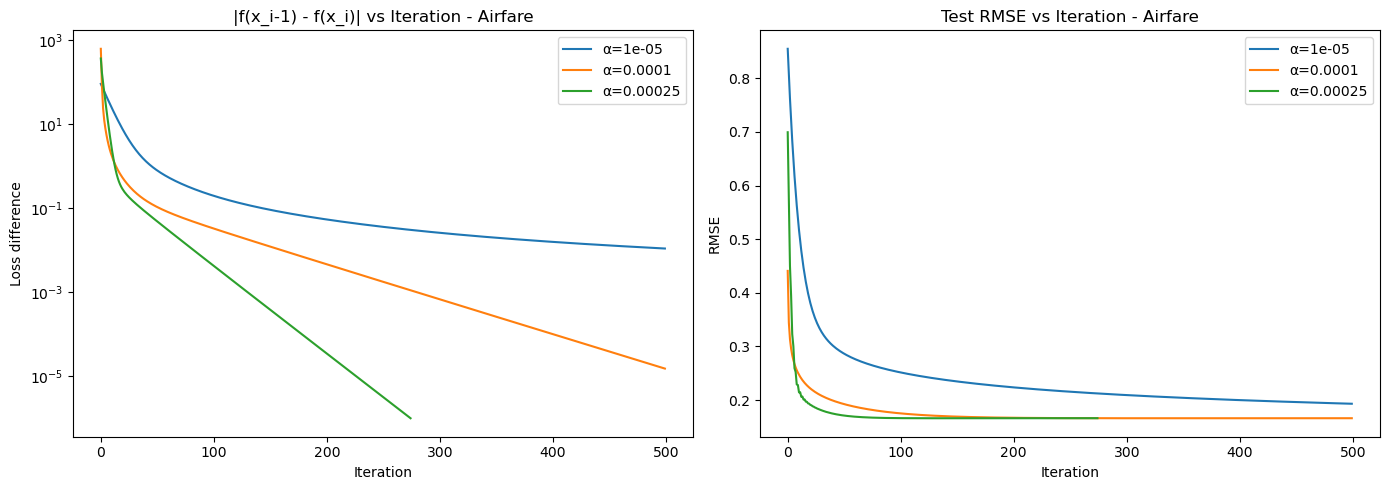

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for alpha in alphas:
    axes[0].plot(results_air[alpha]['loss_diffs'], label=f'α={alpha}')
    axes[1].plot(results_air[alpha]['rmses'],      label=f'α={alpha}')

axes[0].set_title('|f(x_i-1) - f(x_i)| vs Iteration - Airfare')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Loss difference')
axes[0].legend()
axes[0].set_yscale('log')

axes[1].set_title('Test RMSE vs Iteration - Airfare')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('RMSE')
axes[1].legend()

plt.tight_layout()
plt.savefig('fig_airfare_fixed.png', dpi=150)
plt.show()

In [19]:
lambda_max_red = np.linalg.eigvalsh(X_red_train_np.T @ X_red_train_np).max()
lambda_max_white = np.linalg.eigvalsh(X_white_train_np.T @ X_white_train_np).max()

print(f"Red wine   - max eigenvalue: {lambda_max_red:.4f}, safe alpha: {1/lambda_max_red:.6f}")
print(f"White wine - max eigenvalue: {lambda_max_white:.4f}, safe alpha: {1/lambda_max_white:.6f}")


Red wine   - max eigenvalue: 3951.5561, safe alpha: 0.000253
White wine - max eigenvalue: 12669.8732, safe alpha: 0.000079


In [20]:
alphas_red   = [1e-5, 1e-4, 2e-4]
alphas_white = [1e-6, 3e-5, 7e-5]

results_red   = {}
results_white = {}

for alpha in alphas_red:
    beta, loss_diffs, rmses = learn_linreg_gd(
        X_red_train_np, y_red_train_np,
        X_red_test_np,  y_red_test_np,
        fixed_step(alpha), imax=500, epsilon=1e-6
    )
    results_red[alpha] = {'loss_diffs': loss_diffs, 'rmses': rmses}
    print(f"Red   alpha={alpha}: iterations={len(rmses)}, final RMSE={rmses[-1]:.4f}")

for alpha in alphas_white:
    beta, loss_diffs, rmses = learn_linreg_gd(
        X_white_train_np, y_white_train_np,
        X_white_test_np,  y_white_test_np,
        fixed_step(alpha), imax=500, epsilon=1e-6
    )
    results_white[alpha] = {'loss_diffs': loss_diffs, 'rmses': rmses}
    print(f"White alpha={alpha}: iterations={len(rmses)}, final RMSE={rmses[-1]:.4f}")


Red   alpha=1e-05: iterations=500, final RMSE=0.7260
Converged at iteration 344
Red   alpha=0.0001: iterations=344, final RMSE=0.7265
Converged at iteration 183
Red   alpha=0.0002: iterations=183, final RMSE=0.7265
White alpha=1e-06: iterations=500, final RMSE=0.8414
White alpha=3e-05: iterations=500, final RMSE=0.8373
White alpha=7e-05: iterations=500, final RMSE=0.8373


In [21]:
beta, loss_diffs, rmses = learn_linreg_gd(
    X_red_train_np, y_red_train_np,
    X_red_test_np,  y_red_test_np,
    fixed_step(0.01),
    imax=500, epsilon=1e-6
)
print(f"First 5 RMSE values: {rmses[:5]}")
print(f"Last RMSE value: {rmses[-1]}")


First 5 RMSE values: [25.878670208555107, 1282.558848820312, 71729.26657552092, 4587933.7179397335, 324367717.2144923]
Last RMSE value: nan


C:\Users\Admin\AppData\Local\Temp\ipykernel_10568\2221934844.py:7: RuntimeWarning: overflow encountered in matmul
  return residuals @ residuals
C:\Users\Admin\AppData\Local\Temp\ipykernel_10568\4054294137.py:17: RuntimeWarning: overflow encountered in square
  rmse = np.sqrt(np.mean((y_test - y_pred)**2))
c:\Users\Admin\anaconda3\lib\site-packages\numpy\core\_methods.py:180: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Admin\AppData\Local\Temp\ipykernel_10568\4054294137.py:14: RuntimeWarning: invalid value encountered in double_scalars
  loss_diffs.append(abs(f_prev - f_curr))
C:\Users\Admin\AppData\Local\Temp\ipykernel_10568\4054294137.py:20: RuntimeWarning: invalid value encountered in double_scalars
  if 0 <= f_prev - f_curr < epsilon:
C:\Users\Admin\AppData\Local\Temp\ipykernel_10568\2221934844.py:11: RuntimeWarning: overflow encountered in matmul
  return -2 * X_train.T @ residuals
C:\Users\Admin\AppData\Loc

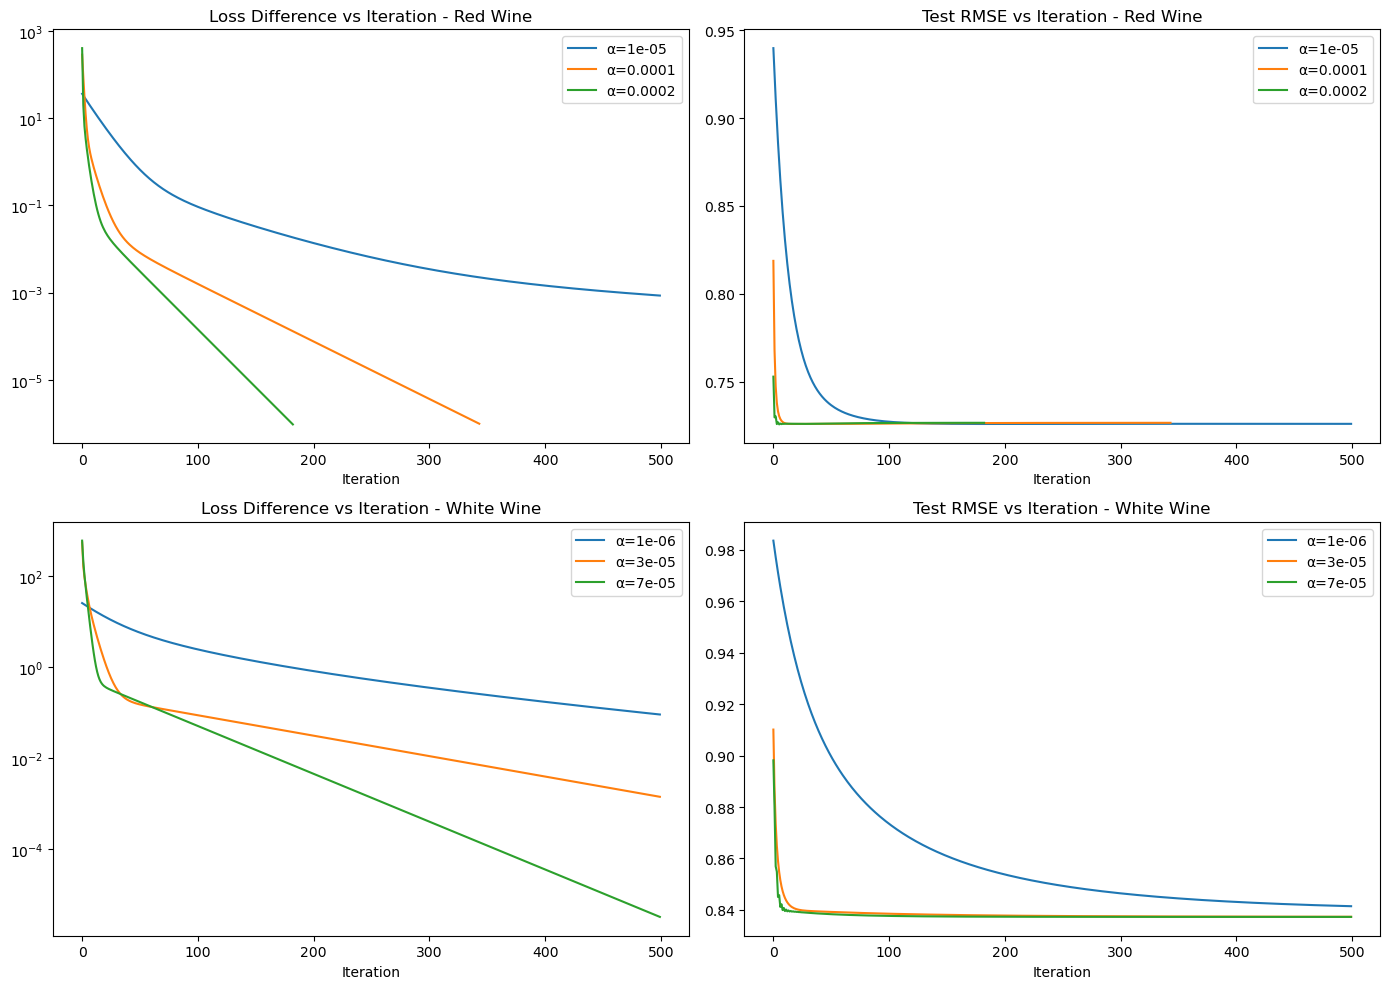

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for alpha in alphas_red:
    axes[0][0].plot(results_red[alpha]['loss_diffs'], label=f'α={alpha}')
    axes[0][1].plot(results_red[alpha]['rmses'],      label=f'α={alpha}')

for alpha in alphas_white:
    axes[1][0].plot(results_white[alpha]['loss_diffs'], label=f'α={alpha}')
    axes[1][1].plot(results_white[alpha]['rmses'],      label=f'α={alpha}')

axes[0][0].set_title('Loss Difference vs Iteration - Red Wine')
axes[0][1].set_title('Test RMSE vs Iteration - Red Wine')
axes[1][0].set_title('Loss Difference vs Iteration - White Wine')
axes[1][1].set_title('Test RMSE vs Iteration - White Wine')

for ax in axes.flat:
    ax.set_xlabel('Iteration')
    ax.legend()

axes[0][0].set_yscale('log')
axes[1][0].set_yscale('log')

plt.tight_layout()
plt.savefig('fig_wine_fixed.png', dpi=150)
plt.show()

In [23]:
def steplength_armijo(f, x, d, delta=0.1):
    alpha = 1.0
    while f(x) - f(x + alpha * d) < alpha * delta * (d @ d):
        alpha = alpha / 2
    return alpha

armijo_step = lambda f, x, d: steplength_armijo(f, x, d, delta=0.1)


In [24]:
def steplength_bolddriver(f, x, d, alpha_old, alpha_plus=1.1, alpha_minus=0.5):
    alpha = alpha_old * alpha_plus
    while f(x) - f(x + alpha * d) <= 0:
        alpha = alpha * alpha_minus
    return alpha

def make_bolddriver(alpha_init=0.1, alpha_plus=1.1, alpha_minus=0.5):
    state = [alpha_init]
    def step(f, x, d):
        alpha = steplength_bolddriver(f, x, d, state[0], alpha_plus, alpha_minus)
        state[0] = alpha
        return alpha
    return step


In [30]:
results_air_armijo = {}
results_air_bold   = {}

beta, loss_diffs, rmses = learn_linreg_gd(
    X_air_train_np, y_air_train_np,
    X_air_test_np,  y_air_test_np,
    armijo_step,
    imax=500, epsilon=1e-6
)
results_air_armijo = {'loss_diffs': loss_diffs, 'rmses': rmses}
print(f"Armijo   - iterations={len(rmses)}, final RMSE={rmses[-1]:.4f}")

beta, loss_diffs, rmses = learn_linreg_gd(
    X_air_train_np, y_air_train_np,
    X_air_test_np,  y_air_test_np,
    make_bolddriver(alpha_init=0.1),
    imax=500, epsilon=1e-6
)
results_air_bold = {'loss_diffs': loss_diffs, 'rmses': rmses}
print(f"BoldDriver - iterations={len(rmses)}, final RMSE={rmses[-1]:.4f}")


Converged at iteration 220
Armijo   - iterations=220, final RMSE=0.1661
Converged at iteration 224
BoldDriver - iterations=224, final RMSE=0.1661


In [26]:
results_red_armijo  = {}
results_red_bold    = {}
results_white_armijo = {}
results_white_bold   = {}

beta, loss_diffs, rmses = learn_linreg_gd(
    X_red_train_np, y_red_train_np,
    X_red_test_np,  y_red_test_np,
    armijo_step, imax=500, epsilon=1e-6
)
results_red_armijo = {'loss_diffs': loss_diffs, 'rmses': rmses}
print(f"Red Armijo    - iterations={len(rmses)}, final RMSE={rmses[-1]:.4f}")

beta, loss_diffs, rmses = learn_linreg_gd(
    X_red_train_np, y_red_train_np,
    X_red_test_np,  y_red_test_np,
    make_bolddriver(alpha_init=0.1), imax=500, epsilon=1e-6
)
results_red_bold = {'loss_diffs': loss_diffs, 'rmses': rmses}
print(f"Red BoldDriver - iterations={len(rmses)}, final RMSE={rmses[-1]:.4f}")

beta, loss_diffs, rmses = learn_linreg_gd(
    X_white_train_np, y_white_train_np,
    X_white_test_np,  y_white_test_np,
    armijo_step, imax=500, epsilon=1e-6
)
results_white_armijo = {'loss_diffs': loss_diffs, 'rmses': rmses}
print(f"White Armijo    - iterations={len(rmses)}, final RMSE={rmses[-1]:.4f}")

beta, loss_diffs, rmses = learn_linreg_gd(
    X_white_train_np, y_white_train_np,
    X_white_test_np,  y_white_test_np,
    make_bolddriver(alpha_init=0.1), imax=500, epsilon=1e-6
)
results_white_bold = {'loss_diffs': loss_diffs, 'rmses': rmses}
print(f"White BoldDriver - iterations={len(rmses)}, final RMSE={rmses[-1]:.4f}")


Converged at iteration 115
Red Armijo    - iterations=115, final RMSE=0.7265
Converged at iteration 115
Red BoldDriver - iterations=115, final RMSE=0.7265
Converged at iteration 420
White Armijo    - iterations=420, final RMSE=0.8373
Converged at iteration 437
White BoldDriver - iterations=437, final RMSE=0.8373


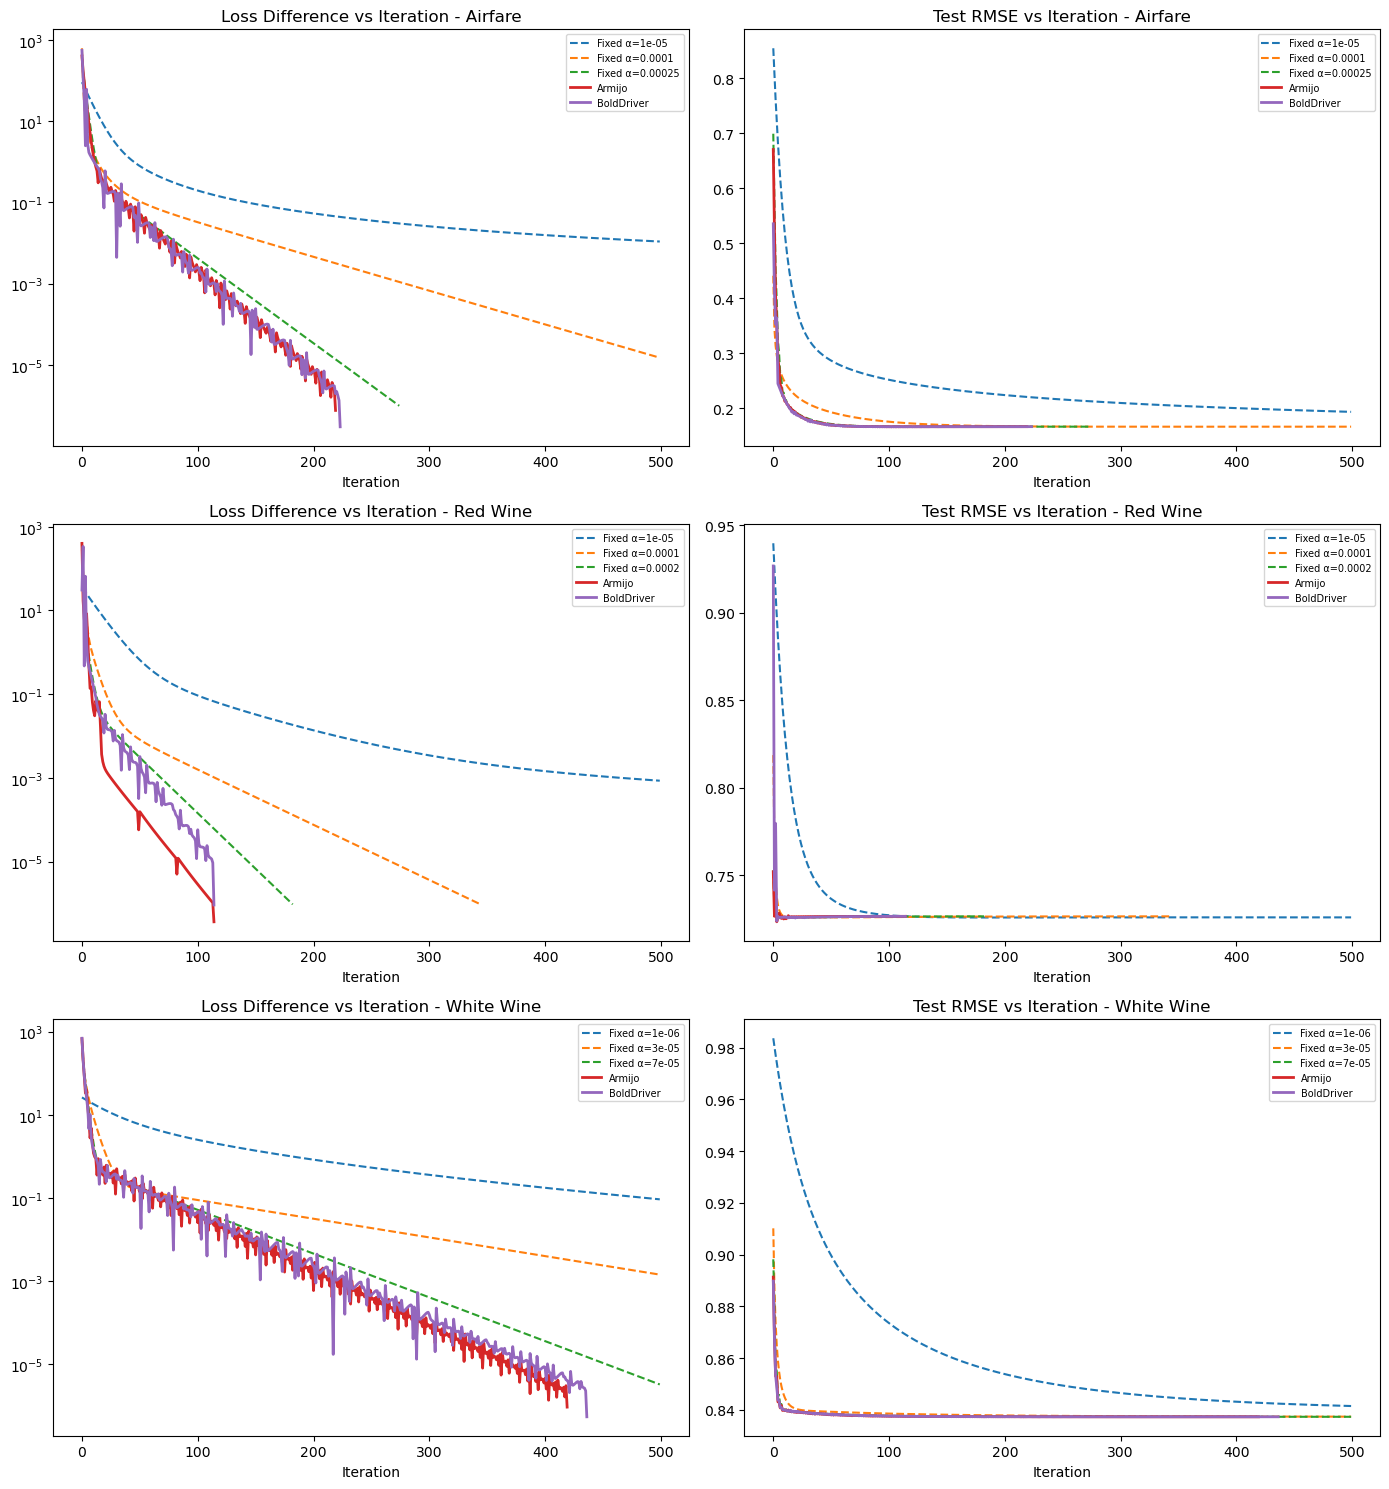

In [27]:
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

datasets = [
    ('Airfare',     results_air,   alphas,       results_air_armijo,   results_air_bold),
    ('Red Wine',    results_red,   alphas_red,   results_red_armijo,   results_red_bold),
    ('White Wine',  results_white, alphas_white, results_white_armijo, results_white_bold),
]

for row, (name, fixed_results, fixed_alphas, armijo_res, bold_res) in enumerate(datasets):
    for alpha in fixed_alphas:
        axes[row][0].plot(fixed_results[alpha]['loss_diffs'], label=f'Fixed α={alpha}', linestyle='--')
        axes[row][1].plot(fixed_results[alpha]['rmses'],      label=f'Fixed α={alpha}', linestyle='--')

    axes[row][0].plot(armijo_res['loss_diffs'], label='Armijo',     linewidth=2)
    axes[row][1].plot(armijo_res['rmses'],      label='Armijo',     linewidth=2)
    axes[row][0].plot(bold_res['loss_diffs'],   label='BoldDriver', linewidth=2)
    axes[row][1].plot(bold_res['rmses'],        label='BoldDriver', linewidth=2)

    axes[row][0].set_title(f'Loss Difference vs Iteration - {name}')
    axes[row][1].set_title(f'Test RMSE vs Iteration - {name}')
    axes[row][0].set_yscale('log')

for ax in axes.flat:
    ax.set_xlabel('Iteration')
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig('fig_comparison.png', dpi=150)
plt.show()

In [28]:
import time

datasets_compare = [
    ('Airfare',    X_air_train_np,   y_air_train_np,   X_air_test_np,   y_air_test_np),
    ('Red Wine',   X_red_train_np,   y_red_train_np,   X_red_test_np,   y_red_test_np),
    ('White Wine', X_white_train_np, y_white_train_np, X_white_test_np, y_white_test_np),
]

print(f"{'Dataset':<12} {'GD RMSE':>10} {'Analytical RMSE':>16} {'GD Time (s)':>12} {'Analytical Time (s)':>20}")
print("-" * 75)

for name, X_tr, y_tr, X_te, y_te in datasets_compare:
    t0 = time.time()
    _, _, rmses_gd = learn_linreg_gd(X_tr, y_tr, X_te, y_te,
                                      armijo_step, imax=500, epsilon=1e-6)
    t_gd = time.time() - t0

    t0 = time.time()
    beta_analytical, _, _, _ = np.linalg.lstsq(X_tr, y_tr, rcond=None)
    t_analytical = time.time() - t0

    y_pred_analytical = X_te @ beta_analytical
    rmse_analytical = np.sqrt(np.mean((y_te - y_pred_analytical)**2))

    print(f"{name:<12} {rmses_gd[-1]:>10.4f} {rmse_analytical:>16.4f} {t_gd:>12.4f} {t_analytical:>20.4f}")

Dataset         GD RMSE  Analytical RMSE  GD Time (s)  Analytical Time (s)
---------------------------------------------------------------------------
Converged at iteration 220
Airfare          0.1661           0.1661       0.3988               0.0122
Converged at iteration 115
Red Wine         0.7265           0.7266       0.0451               0.0010
Converged at iteration 420
White Wine       0.8373           0.8373       0.3168               0.0010
